# ⚖️ EVALUASI v3 — Baseline (Naive, GARCH) + Uji Diebold–Mariano + Karakteristik Emiten
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

Menggantikan `Baseline_GARCH_Volatility_LQ45.ipynb`. Seluruh model dievaluasi pada **tanggal uji yang identik** (1.500 hari-emiten).

| Model | Sumber prediksi |
|---|---|
| Naive | σ̂_{t+1} = σ_t (`Vol_Lag1`) |
| GARCH(1,1)-t | `GARCH_Forecast` dari PREP_01 v4 (expanding window, re-estimasi tiap 20 hari — **definisi yang sama** dengan fitur hybrid) |
| XGBoost hybrid | `hasil_prediksi_xgboost.csv` (MODEL_xgboost v4) |
| LSTM hybrid | `hasil_prediksi_lstm.csv` (MODEL_lstm v5) |

**Keluaran:** Tabel performa (→ Tabel VI), uji DM per emiten & gabungan (→ Reviewer 1 #2, Reviewer 2 #1), parameter GARCH (→ Tabel 4.x tesis), karakteristik volatilitas per emiten (→ Reviewer 2 #5), grafik aktual vs prediksi.

## ⚙️ CELL 1 — Konfigurasi & Muat Data

In [67]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
warnings.filterwarnings('ignore')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 9, 'figure.dpi': 150})

ROOT = Path.cwd()
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')
DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR): d.mkdir(parents=True, exist_ok=True)
URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
KOLOM_Y = 'Volatilitas_Target'

def inverse_transform(v, sc, kolom):
    cmin, cmax = float(sc.loc[kolom, 'min']), float(sc.loc[kolom, 'max'])
    return np.asarray(v, float) * (cmax - cmin) + cmin

rows = []
for e in URUTAN_EMITEN:
    te = pd.read_csv(DIR_FINAL / f'dataset_test_{e}.csv', encoding='utf-8-sig', parse_dates=['Date'])
    sc = pd.read_csv(DIR_FINAL / f'scaler_params_{e}.csv', index_col=0, encoding='utf-8-sig')
    rows.append(pd.DataFrame({'Emiten': e, 'Date': te['Date'],
                              'Aktual': inverse_transform(te[KOLOM_Y], sc, KOLOM_Y),
                              'Naive': inverse_transform(te['Vol_Lag1'], sc, 'Vol_Lag1'),
                              'GARCH(1,1)': inverse_transform(te['GARCH_Forecast'], sc, 'GARCH_Forecast')}))
df = pd.concat(rows, ignore_index=True)

for nama, f in [('XGBoost', 'hasil_prediksi_xgboost.csv'), ('LSTM', 'hasil_prediksi_lstm.csv')]:
    p = pd.read_csv(DIR_TABEL / f, encoding='utf-8-sig', parse_dates=['Date'])
    p = p[['Emiten', 'Date', 'Y_Aktual', 'Y_Prediksi']].rename(columns={'Y_Prediksi': nama, 'Y_Aktual': f'_akt_{nama}'})
    n_awal = len(df)
    df = df.merge(p, on=['Emiten', 'Date'], how='left', validate='one_to_one')
    assert len(df) == n_awal, f'{nama}: jumlah baris berubah setelah penggabungan'
    assert df[nama].notna().all(), f'{nama}: ada tanggal uji tanpa prediksi → jalankan ulang notebook model versi terbaru'
    assert np.allclose(df[f'_akt_{nama}'], df['Aktual'], rtol=1e-6), f'{nama}: nilai aktual tidak cocok'
    df = df.drop(columns=f'_akt_{nama}')

MODELS = ['Naive', 'GARCH(1,1)', 'XGBoost', 'LSTM']
print(f'✅ {len(df):,} hari-emiten | tanggal uji identik untuk {MODELS}')

✅ 1,500 hari-emiten | tanggal uji identik untuk ['Naive', 'GARCH(1,1)', 'XGBoost', 'LSTM']


In [68]:
# ==============================================================================
# CELL 1B — Validasi alignment & struktur data uji
# ==============================================================================
cek = []
for e in URUTAN_EMITEN:
    g = df[df.Emiten == e]
    tr_end = pd.read_csv(DIR_FINAL / f'dataset_train_{e}.csv', usecols=['Date'], parse_dates=['Date'])['Date'].max()
    cek.append({'Emiten': e, 'n': len(g), 'Awal uji': g.Date.min().date(), 'Akhir uji': g.Date.max().date(),
                'Akhir latih': tr_end.date(), 'Duplikat tanggal': int(g.Date.duplicated().sum()),
                'Terurut': bool(g.Date.is_monotonic_increasing),
                **{f'n {m}': int(g[m].notna().sum()) for m in MODELS}})
cek = pd.DataFrame(cek)
print(cek.to_string(index=False))

assert cek['Duplikat tanggal'].sum() == 0, 'Ada duplikasi tanggal per emiten'
assert cek['Terurut'].all(), 'Tanggal tidak terurut'
assert (pd.to_datetime(cek['Awal uji']) > pd.to_datetime(cek['Akhir latih'])).all(), 'Periode uji tumpang tindih dengan latih'
for m in MODELS:
    assert (cek[f'n {m}'] == cek['n']).all(), f'{m}: jumlah observasi tidak sama dengan aktual'

tgl = pd.DatetimeIndex(df.Date.unique()).sort_values()
hilang = {e: int((~tgl.isin(df.loc[df.Emiten == e, 'Date'])).sum()) for e in URUTAN_EMITEN}
print(f'\nKalender gabungan: {len(tgl)} tanggal | tanggal tanpa observasi per emiten: {hilang}')
print(f'✅ Alignment valid: {len(df):,} observasi identik untuk {MODELS}')

Emiten   n   Awal uji  Akhir uji Akhir latih  Duplikat tanggal  Terurut  n Naive  n GARCH(1,1)  n XGBoost  n LSTM
  ADRO 215 2025-08-08 2026-06-30  2025-08-07                 0     True      215           215        215     215
  ADMR 210 2025-08-15 2026-06-30  2025-08-14                 0     True      210           210        210     210
  ITMG 215 2025-08-08 2026-06-30  2025-08-07                 0     True      215           215        215     215
  PTBA 215 2025-08-08 2026-06-30  2025-08-07                 0     True      215           215        215     215
  MEDC 215 2025-08-08 2026-06-30  2025-08-07                 0     True      215           215        215     215
  AKRA 215 2025-08-08 2026-06-30  2025-08-07                 0     True      215           215        215     215
  PGAS 215 2025-08-08 2026-06-30  2025-08-07                 0     True      215           215        215     215

Kalender gabungan: 215 tanggal | tanggal tanpa observasi per emiten: {'ADRO': 0, 'ADMR'

## 📋 CELL 2 — Tabel Performa (→ Tabel VI artikel)

In [69]:
# ==============================================================================
# CELL 2 — Tabel Performa + validasi prediksi + QLIKE ternormalisasi (Patton, 2011)
# ==============================================================================
# Tidak ada clipping maupun batas bawah numerik (epsilon/floor). Prediksi <= 0, NaN,
# atau inf menghentikan proses dengan pesan eksplisit agar masalah data terlihat.

def validasi_prediksi(df, kolom):
    """Laporan integritas: jumlah NaN, inf, nol, dan negatif per kolom (aktual & model)."""
    rows = []
    for c in kolom:
        x = df[c].to_numpy(float)
        rows.append({'Kolom': c, 'n': len(x), 'NaN': int(np.isnan(x).sum()),
                     'Inf': int(np.isinf(x).sum()), 'Nol': int((x == 0).sum()),
                     'Negatif': int((x < 0).sum()),
                     'Min': float(np.nanmin(x)), 'Maks': float(np.nanmax(x))})
    return pd.DataFrame(rows)

def qlike_loss(y, p):
    """QLIKE ternormalisasi per observasi: r - ln(r) - 1, dengan r = y² / p².
    y dan p WAJIB volatilitas (standar deviasi) pada skala asli yang sama, bukan varians.
    Tanpa clipping maupun batas bawah numerik. Nilai >= 0; 0 berarti prediksi sempurna."""
    y = np.asarray(y, float)
    p = np.asarray(p, float)

    if not (np.isfinite(y).all() and np.isfinite(p).all()):
        raise ValueError('QLIKE: terdapat NaN/inf pada aktual atau prediksi')

    if (p <= 0).any() or (y <= 0).any():
        raise ValueError(f'QLIKE: {int((p <= 0).sum())} prediksi dan {int((y <= 0).sum())} aktual bernilai <= 0')

    r = (y / p) ** 2
    return r - np.log(r) - 1

def _mape(y, p):
    y = np.asarray(y, float); p = np.asarray(p, float)
    if (y == 0).any():
        raise ValueError('MAPE: terdapat nilai aktual = 0')
    return float(np.mean(np.abs((y - p) / y)) * 100)

def metrik(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {'RMSE (1e-3)': np.sqrt(mean_squared_error(y, p)) * 1e3,
            'MAE (1e-3)': mean_absolute_error(y, p) * 1e3,
            'MAPE (%)': _mape(y, p), 'R2': r2_score(y, p),
            'QLIKE': float(np.mean(qlike_loss(y, p)))}

# ── 1. Validasi integritas data sebelum evaluasi
lap = validasi_prediksi(df, ['Aktual'] + MODELS)
print('Validasi prediksi (jumlah nilai bermasalah per kolom):')
print(lap.to_string(index=False))
assert (lap[['NaN', 'Inf', 'Nol', 'Negatif']].sum().sum() == 0), 'Ada nilai tidak valid — lihat tabel di atas'
print('✅ Seluruh aktual & prediksi valid (tanpa NaN/inf/nol/negatif); tanpa clipping maupun floor.\n')

# ── 2. Tabel performa per model & emiten
tab = []
for m in MODELS:
    for e in URUTAN_EMITEN:
        g = df[df.Emiten == e]
        tab.append({'Model': m, 'Emiten': e, **metrik(g.Aktual, g[m])})
tab = pd.DataFrame(tab)
avg = tab.groupby('Model', sort=False).mean(numeric_only=True).reset_index().assign(Emiten='Average')
tab = pd.concat([tab, avg], ignore_index=True)
tab['_o'] = tab.Model.map({m: i for i, m in enumerate(MODELS)})
tab = tab.sort_values(['_o'], kind='stable').drop(columns='_o').reset_index(drop=True)
tab.round(6).to_csv(DIR_TABEL / 'tabel_performa_semua_model.csv', index=False, encoding='utf-8-sig')

tampil = tab.copy(); tampil['QLIKE (1e-3)'] = tampil.pop('QLIKE') * 1e3
pd.set_option('display.width', 200, 'display.max_columns', None)
print(tampil.round({'RMSE (1e-3)': 3, 'MAE (1e-3)': 3, 'MAPE (%)': 2, 'R2': 4, 'QLIKE (1e-3)': 2}).to_string(index=False))
print('\nQLIKE ternormalisasi: >= 0, semakin kecil semakin baik (ditampilkan ×10⁻³).')

# ── 3. Validasi matematis QLIKE: r - ln r - 1 >= 0 untuk setiap observasi
TOL = 1e-12   # toleransi pembulatan floating-point, hanya untuk pengecekan (tidak mengubah nilai)
for m in MODELS:
    loss = qlike_loss(df['Aktual'].to_numpy(), df[m].to_numpy())
    assert len(loss) == len(df), f'{m}: jumlah loss tidak sama dengan jumlah observasi'
    assert np.isfinite(loss).all(), f'{m}: QLIKE mengandung NaN/inf'
    assert (loss >= -TOL).all(), f'{m}: QLIKE negatif (min = {loss.min():.2e})'
    print(f'  ✅ {m:11s}: n = {len(loss):,} | QLIKE min = {loss.min():.2e} | maks = {loss.max():.4f}')
print('✅ QLIKE valid secara matematis untuk seluruh model (semua nilai >= 0).')

Validasi prediksi (jumlah nilai bermasalah per kolom):
     Kolom    n  NaN  Inf  Nol  Negatif      Min     Maks
    Aktual 1500    0    0    0        0 0.004436 0.069340
     Naive 1500    0    0    0        0 0.004436 0.069340
GARCH(1,1) 1500    0    0    0        0 0.004289 0.069995
   XGBoost 1500    0    0    0        0 0.004063 0.069780
      LSTM 1500    0    0    0        0 0.004216 0.070332
✅ Seluruh aktual & prediksi valid (tanpa NaN/inf/nol/negatif); tanpa clipping maupun floor.

     Model  Emiten  RMSE (1e-3)  MAE (1e-3)  MAPE (%)     R2  QLIKE (1e-3)
     Naive    ADRO        1.858       0.960      4.18 0.9131         14.67
     Naive    ADMR        3.615       1.680      4.81 0.9368         30.85
     Naive    ITMG        1.357       0.674      4.85 0.9794         20.96
     Naive    PTBA        1.556       0.720      4.75 0.9653         23.90
     Naive    MEDC        2.476       1.220      4.07 0.9346         11.89
     Naive    AKRA        1.587       0.943      4.25 

## 🧪 CELL 3 — Uji Diebold–Mariano (MSE loss, koreksi Harvey–Leybourne–Newbold)
DM < 0 → model pertama lebih akurat. Diuji per emiten dan **gabungan 7 emiten** (loss dinormalisasi dengan varians target uji per emiten agar skala setara).

In [70]:
# ==============================================================================
# CELL 3 — Uji Diebold–Mariano (DM standar + koreksi Harvey–Leybourne–Newbold)
#   • Per emiten : deret loss differential masing-masing emiten
#   • Gabungan   : rata-rata loss differential lintas emiten PER TANGGAL (1 deret harian),
#                  bukan penumpukan vertikal 7 emiten
#   • Holm–Bonferroni untuk 6 pasangan model dalam setiap (loss, emiten/gabungan)
# ==============================================================================
from scipy import stats

def dm_test(d, h=1):
    """Uji Diebold–Mariano standar dengan koreksi sampel kecil Harvey–Leybourne–Newbold.
    d_t = loss(model 1) − loss(model 2). Untuk h = 1, varians d̄ = var(d)/n (tanpa lag).
    DM < 0 → rata-rata loss model 1 lebih kecil (model 1 lebih akurat). Uji dua sisi, t(n−1)."""
    d = np.asarray(d, float)
    if not np.isfinite(d).all():
        raise ValueError('DM: loss differential mengandung NaN/inf')
    n, dbar = len(d), d.mean()
    gamma = [np.sum((d[k:] - dbar) * (d[:n - k] - dbar)) / n for k in range(h)]
    var = (gamma[0] + 2 * sum(gamma[1:])) / n
    if var <= 0:
        return 0.0, 1.0
    stat = dbar / np.sqrt(var) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return float(stat), float(2 * stats.t.sf(abs(stat), df=n - 1))

def holm(p):
    """p-value terkoreksi Holm–Bonferroni."""
    p = np.asarray(p, float); urut = np.argsort(p); m = len(p)
    adj = np.empty(m); maks = 0.0
    for i, j in enumerate(urut):
        maks = max(maks, (m - i) * p[j]); adj[j] = min(maks, 1.0)
    return adj

LOSS = {'MSE':   lambda y, p: (np.asarray(y, float) - np.asarray(p, float)) ** 2,
        'MAE':   lambda y, p: np.abs(np.asarray(y, float) - np.asarray(p, float)),
        'QLIKE': qlike_loss}                                   # fungsi terpusat CELL 2
# Normalisasi skala antaremiten sebelum dirata-rata (QLIKE sudah bebas skala)
NORM = {'MSE': lambda y: np.var(y, ddof=1), 'MAE': lambda y: np.std(y, ddof=1), 'QLIKE': lambda y: 1.0}
PASANGAN = [('XGBoost', 'GARCH(1,1)'), ('LSTM', 'GARCH(1,1)'), ('XGBoost', 'Naive'),
            ('LSTM', 'Naive'), ('GARCH(1,1)', 'Naive'), ('XGBoost', 'LSTM')]

def uji_dm(nama_loss):
    f, norm = LOSS[nama_loss], NORM[nama_loss]
    rows = []
    for a, b in PASANGAN:
        harian = {}
        for e in URUTAN_EMITEN:
            g = df[df.Emiten == e].sort_values('Date')
            d = np.asarray(f(g.Aktual, g[a]) - f(g.Aktual, g[b]), float)
            s, p = dm_test(d)
            rows.append({'Loss': nama_loss, 'Emiten': e, 'Model 1': a, 'Model 2': b,
                         'n': len(d), 'DM': s, 'p_value': p})
            harian[e] = pd.Series(d / norm(g.Aktual.to_numpy(float)), index=g.Date.values)
        panel = pd.DataFrame(harian).sort_index()          # baris = tanggal, kolom = emiten
        panel = panel.dropna(axis=0, how='any')            # panel seimbang: hanya tanggal dengan ketujuh emiten
        d_avg = panel.mean(axis=1)                         # rata-rata lintas emiten per tanggal (n = 210)
        d_avg = panel.mean(axis=1, skipna=True)            # rata-rata lintas emiten per tanggal
        s, p = dm_test(d_avg.to_numpy())
        rows.append({'Loss': nama_loss, 'Emiten': 'Gabungan', 'Model 1': a, 'Model 2': b,
                     'n': len(d_avg), 'DM': s, 'p_value': p})
    out = pd.DataFrame(rows)
    out['p_holm'] = out.groupby('Emiten')['p_value'].transform(holm)
    out['Kesimpulan'] = np.where(out.p_value >= 0.05, 'tidak berbeda signifikan',
                         np.where(out.DM < 0, out['Model 1'] + ' lebih akurat', out['Model 2'] + ' lebih akurat'))
    out['Signifikan_Holm'] = out.p_holm < 0.05
    return out

def cetak_dm(t, judul):
    t = t.assign(P=t['Model 1'] + ' vs ' + t['Model 2'])
    tab_ = (t.pivot(index='Emiten', columns='P', values='DM').round(2).astype(str) + ' ('
            + t.pivot(index='Emiten', columns='P', values='p_value').round(3).astype(str) + ')')
    print(f'\n=== {judul} — DM (p-value), DM<0: model 1 lebih akurat ===')
    print(tab_.reindex(URUTAN_EMITEN + ['Gabungan'])[[f'{a} vs {b}' for a, b in PASANGAN]].to_string())

pd.set_option('display.width', 220, 'display.max_columns', None)
df_dm = uji_dm('MSE')
df_dm.round(4).to_csv(DIR_TABEL / 'tabel_uji_dm_semua_model.csv', index=False, encoding='utf-8-sig')
cetak_dm(df_dm, 'Loss MSE (DM standar + koreksi HLN)')
print('\nGabungan 7 emiten (rata-rata harian lintas emiten):')
print(df_dm[df_dm.Emiten == 'Gabungan'][['Model 1', 'Model 2', 'DM', 'p_value', 'p_holm', 'Kesimpulan', 'Signifikan_Holm']]
      .round(4).to_string(index=False))


=== Loss MSE (DM standar + koreksi HLN) — DM (p-value), DM<0: model 1 lebih akurat ===
P        XGBoost vs GARCH(1,1) LSTM vs GARCH(1,1) XGBoost vs Naive  LSTM vs Naive GARCH(1,1) vs Naive XGBoost vs LSTM
Emiten                                                                                                               
ADRO              2.68 (0.008)       1.16 (0.248)    -2.47 (0.014)  -3.13 (0.002)       -3.33 (0.001)    2.28 (0.024)
ADMR              0.35 (0.726)       0.28 (0.777)    -2.44 (0.016)  -2.46 (0.015)       -2.47 (0.014)    0.17 (0.864)
ITMG             -0.95 (0.343)       1.29 (0.197)    -3.13 (0.002)   -2.61 (0.01)        -3.0 (0.003)   -1.59 (0.114)
PTBA              -0.0 (0.997)      -1.58 (0.115)    -2.74 (0.007)   -3.0 (0.003)       -2.73 (0.007)    1.55 (0.122)
MEDC               2.7 (0.008)       0.42 (0.677)    -2.12 (0.035)  -2.26 (0.025)       -2.28 (0.024)    2.26 (0.025)
AKRA              0.36 (0.719)       0.59 (0.553)      -4.01 (0.0)    -3.96 (0.0)     

In [71]:
# ==============================================================================
# CELL 3B — Uji ketahanan: DM standar (koreksi HLN) untuk loss MSE, MAE, QLIKE
#           per emiten & gabungan (rata-rata harian lintas emiten)
# ==============================================================================
df_dm_rob = pd.concat([uji_dm(n) for n in LOSS], ignore_index=True)
df_dm_rob.round(4).to_csv(DIR_TABEL / 'tabel_uji_dm_robust_loss.csv', index=False, encoding='utf-8-sig')
for n in LOSS:
    cetak_dm(df_dm_rob[df_dm_rob.Loss == n], f'Loss {n}')


=== Loss MSE — DM (p-value), DM<0: model 1 lebih akurat ===
P        XGBoost vs GARCH(1,1) LSTM vs GARCH(1,1) XGBoost vs Naive  LSTM vs Naive GARCH(1,1) vs Naive XGBoost vs LSTM
Emiten                                                                                                               
ADRO              2.68 (0.008)       1.16 (0.248)    -2.47 (0.014)  -3.13 (0.002)       -3.33 (0.001)    2.28 (0.024)
ADMR              0.35 (0.726)       0.28 (0.777)    -2.44 (0.016)  -2.46 (0.015)       -2.47 (0.014)    0.17 (0.864)
ITMG             -0.95 (0.343)       1.29 (0.197)    -3.13 (0.002)   -2.61 (0.01)        -3.0 (0.003)   -1.59 (0.114)
PTBA              -0.0 (0.997)      -1.58 (0.115)    -2.74 (0.007)   -3.0 (0.003)       -2.73 (0.007)    1.55 (0.122)
MEDC               2.7 (0.008)       0.42 (0.677)    -2.12 (0.035)  -2.26 (0.025)       -2.28 (0.024)    2.26 (0.025)
AKRA              0.36 (0.719)       0.59 (0.553)      -4.01 (0.0)    -3.96 (0.0)         -4.03 (0.0)   -0.38 (0.

In [72]:
# ==============================================================================
# CELL 3C — Ringkasan uji gabungan 7 emiten (MSE, MAE, QLIKE) + koreksi Holm
#           DM standar (koreksi HLN); gabungan = rata-rata harian lintas emiten
# ==============================================================================
gab = df_dm_rob[df_dm_rob.Emiten == 'Gabungan'][['Loss', 'Model 1', 'Model 2', 'n', 'DM',
                                                  'p_value', 'p_holm', 'Kesimpulan', 'Signifikan_Holm']]
gab.round(4).to_csv(DIR_TABEL / 'tabel_uji_dm_hac.csv', index=False, encoding='utf-8-sig')
print(gab.round(4).to_string(index=False))
print('\nSignifikansi 5%. p_holm = p-value terkoreksi Holm–Bonferroni untuk 6 pasangan model per loss.')

 Loss    Model 1    Model 2   n      DM  p_value  p_holm               Kesimpulan  Signifikan_Holm
  MSE    XGBoost GARCH(1,1) 210  3.5359   0.0005  0.0015  GARCH(1,1) lebih akurat             True
  MSE       LSTM GARCH(1,1) 210  1.9102   0.0575  0.0603 tidak berbeda signifikan            False
  MSE    XGBoost      Naive 210 -5.5957   0.0000  0.0000     XGBoost lebih akurat             True
  MSE       LSTM      Naive 210 -5.8871   0.0000  0.0000        LSTM lebih akurat             True
  MSE GARCH(1,1)      Naive 210 -6.0881   0.0000  0.0000  GARCH(1,1) lebih akurat             True
  MSE    XGBoost       LSTM 210  2.1829   0.0302  0.0603        LSTM lebih akurat            False
  MAE    XGBoost GARCH(1,1) 210 -4.3364   0.0000  0.0000     XGBoost lebih akurat             True
  MAE       LSTM GARCH(1,1) 210 -4.4333   0.0000  0.0000        LSTM lebih akurat             True
  MAE    XGBoost      Naive 210 -6.2289   0.0000  0.0000     XGBoost lebih akurat             True
  MAE     

## 📐 CELL 4 — Parameter GARCH(1,1)-t pada Data Latih (→ Tabel 4.x tesis)

In [73]:
from arch import arch_model
tek = pd.read_csv(DIR_PROCESSED / 'technical_features.csv', parse_dates=['Date'])
rows = []
for e in URUTAN_EMITEN:
    tr_end = pd.read_csv(DIR_FINAL / f'dataset_train_{e}.csv', parse_dates=['Date'])['Date'].max()
    r = tek[(tek.Emiten == e) & (tek.Date <= tr_end)].sort_values('Date')['Log_Return'].dropna() * 100
    res = arch_model(r.values, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off')
    assert res.convergence_flag == 0, f'{e}: estimasi GARCH tidak konvergen'
    pr, pv = res.params, res.pvalues
    assert pr['alpha[1]'] + pr['beta[1]'] < 1, f'{e}: alpha+beta >= 1 (tidak stasioner), half-life tak terdefinisi'
    rows.append({'Emiten': e, 'n': len(r), 'mu': pr['mu'], 'omega': pr['omega'],
                 'alpha': pr['alpha[1]'], 'p_alpha': pv['alpha[1]'], 'beta': pr['beta[1]'], 'p_beta': pv['beta[1]'],
                 'alpha+beta': pr['alpha[1]'] + pr['beta[1]'], 'nu': pr['nu'],
                 'Half-life (hari)': np.log(0.5) / np.log(pr['alpha[1]'] + pr['beta[1]'])})
df_par = pd.DataFrame(rows)
df_par.round(4).to_csv(DIR_TABEL / 'tabel_parameter_garch.csv', index=False, encoding='utf-8-sig')
print('Return dalam persen (×100). alpha+beta mendekati 1 = volatility clustering kuat.')
print(df_par.round(4).to_string(index=False))

Return dalam persen (×100). alpha+beta mendekati 1 = volatility clustering kuat.
Emiten   n      mu  omega  alpha  p_alpha   beta  p_beta  alpha+beta     nu  Half-life (hari)
  ADRO 859  0.0740 1.4762 0.1541   0.0098 0.6617  0.0000      0.8158 3.6872            3.4049
  ADMR 840 -0.1755 0.0976 0.0234   0.0476 0.9666  0.0000      0.9900 6.0174           68.8409
  ITMG 859  0.0633 0.0254 0.0491   0.0451 0.9467  0.0000      0.9959 4.1841          167.3202
  PTBA 859  0.0036 1.5645 0.1962   0.0335 0.5186  0.1335      0.7148 3.2217            2.0648
  MEDC 859  0.0150 0.8305 0.1132   0.0926 0.8099  0.0000      0.9231 5.5074            8.6599
  AKRA 859  0.0263 0.0759 0.0500   0.1237 0.9446  0.0000      0.9946 3.6349          128.3788
  PGAS 859  0.0126 0.1040 0.0462   0.0731 0.9333  0.0000      0.9794 3.7313           33.3688


## 🔎 CELL 5 — Karakteristik Volatilitas per Emiten vs Kinerja Model (→ Reviewer 2 #5)

In [74]:
# ==============================================================================
# CELL 5 — Karakteristik Volatilitas per Emiten vs Kinerja Model (tanpa R²)
# ==============================================================================
rows = []
for e in URUTAN_EMITEN:
    tr = pd.read_csv(DIR_FINAL / f'dataset_train_{e}.csv', parse_dates=['Date'])
    t = tek[tek.Emiten == e].sort_values('Date')
    v_tr = t[t.Date <= tr.Date.max()]['Volatilitas']
    v_te = t[t.Date > tr.Date.max()]['Volatilitas']
    r_tr = t[t.Date <= tr.Date.max()]['Log_Return']
    rows.append({'Emiten': e, 'n_latih': len(tr), 'Mean vol latih': v_tr.mean(),
                 'Vol-of-vol (std)': v_tr.std(), 'Kurtosis return': r_tr.kurt(),
                 'AC(1) vol': v_tr.autocorr(lag=1),
                 'Mean vol uji / latih': v_te.mean() / v_tr.mean(),
                 'Max vol uji / latih': v_te.max() / v_tr.max()})
df_kar = pd.DataFrame(rows)
df_kar.round(4).to_csv(DIR_TABEL / 'tabel_karakteristik_emiten.csv', index=False, encoding='utf-8-sig')
print(df_kar.round(4).to_string(index=False))

# ── Korelasi Spearman: karakteristik vs MAPE & rasio MAE terhadap Naive ──
print('\nKorelasi Spearman: karakteristik emiten vs MAPE dan rasio MAE terhadap Naive')
k = df_kar.set_index('Emiten').join(df_par.set_index('Emiten')[['Half-life (hari)']])
mape = tab[tab.Emiten != 'Average'].pivot(index='Emiten', columns='Model', values='MAPE (%)')
mae  = tab[tab.Emiten != 'Average'].pivot(index='Emiten', columns='Model', values='MAE (1e-3)')
for m in MODELS: k[f'MAPE {m}'] = mape[m]
for m in ['GARCH(1,1)', 'XGBoost', 'LSTM']: k[f'MAE {m}/Naive'] = mae[m] / mae['Naive']
kar_cols = ['Kurtosis return', 'Vol-of-vol (std)', 'AC(1) vol', 'Half-life (hari)', 'Max vol uji / latih']
hasil = [c for c in k.columns if c.startswith('MAPE ') or c.endswith('/Naive')]
kor = k[kar_cols + hasil].corr(method='spearman').loc[kar_cols, hasil].round(2)
kor.to_csv(DIR_TABEL / 'tabel_korelasi_karakteristik.csv', encoding='utf-8-sig')
print(kor.to_string())

# ── p-value korelasi Spearman (n = 7 emiten)
pval = pd.DataFrame(index=kar_cols, columns=hasil, dtype=float)
for a in kar_cols:
    for b in hasil:
        pval.loc[a, b] = stats.spearmanr(k[a], k[b]).pvalue
pval = pval.round(4)
pval.to_csv(DIR_TABEL / 'tabel_korelasi_karakteristik_pvalue.csv', encoding='utf-8-sig')
print('\np-value korelasi Spearman (n = 7):')
print(pval.to_string())

Emiten  n_latih  Mean vol latih  Vol-of-vol (std)  Kurtosis return  AC(1) vol  Mean vol uji / latih  Max vol uji / latih
  ADRO      859          0.0254            0.0122          16.3885     0.9762                0.9493               0.4649
  ADMR      840          0.0333            0.0116           2.8555     0.9804                1.1397               0.7945
  ITMG      859          0.0189            0.0076           3.7201     0.9830                0.8089               1.0172
  PTBA      859          0.0198            0.0087          12.0801     0.9742                0.8279               0.5608
  MEDC      859          0.0298            0.0100           3.0905     0.9761                1.0563               0.8391
  AKRA      859          0.0242            0.0091           5.8421     0.9771                0.9880               0.5499
  PGAS      859          0.0188            0.0057           2.8208     0.9675                1.1197               1.2695

Korelasi Spearman: karakteristi

## 📊 CELL 6 — Grafik Aktual vs Prediksi (satu emiten untuk artikel, semua emiten untuk tesis)

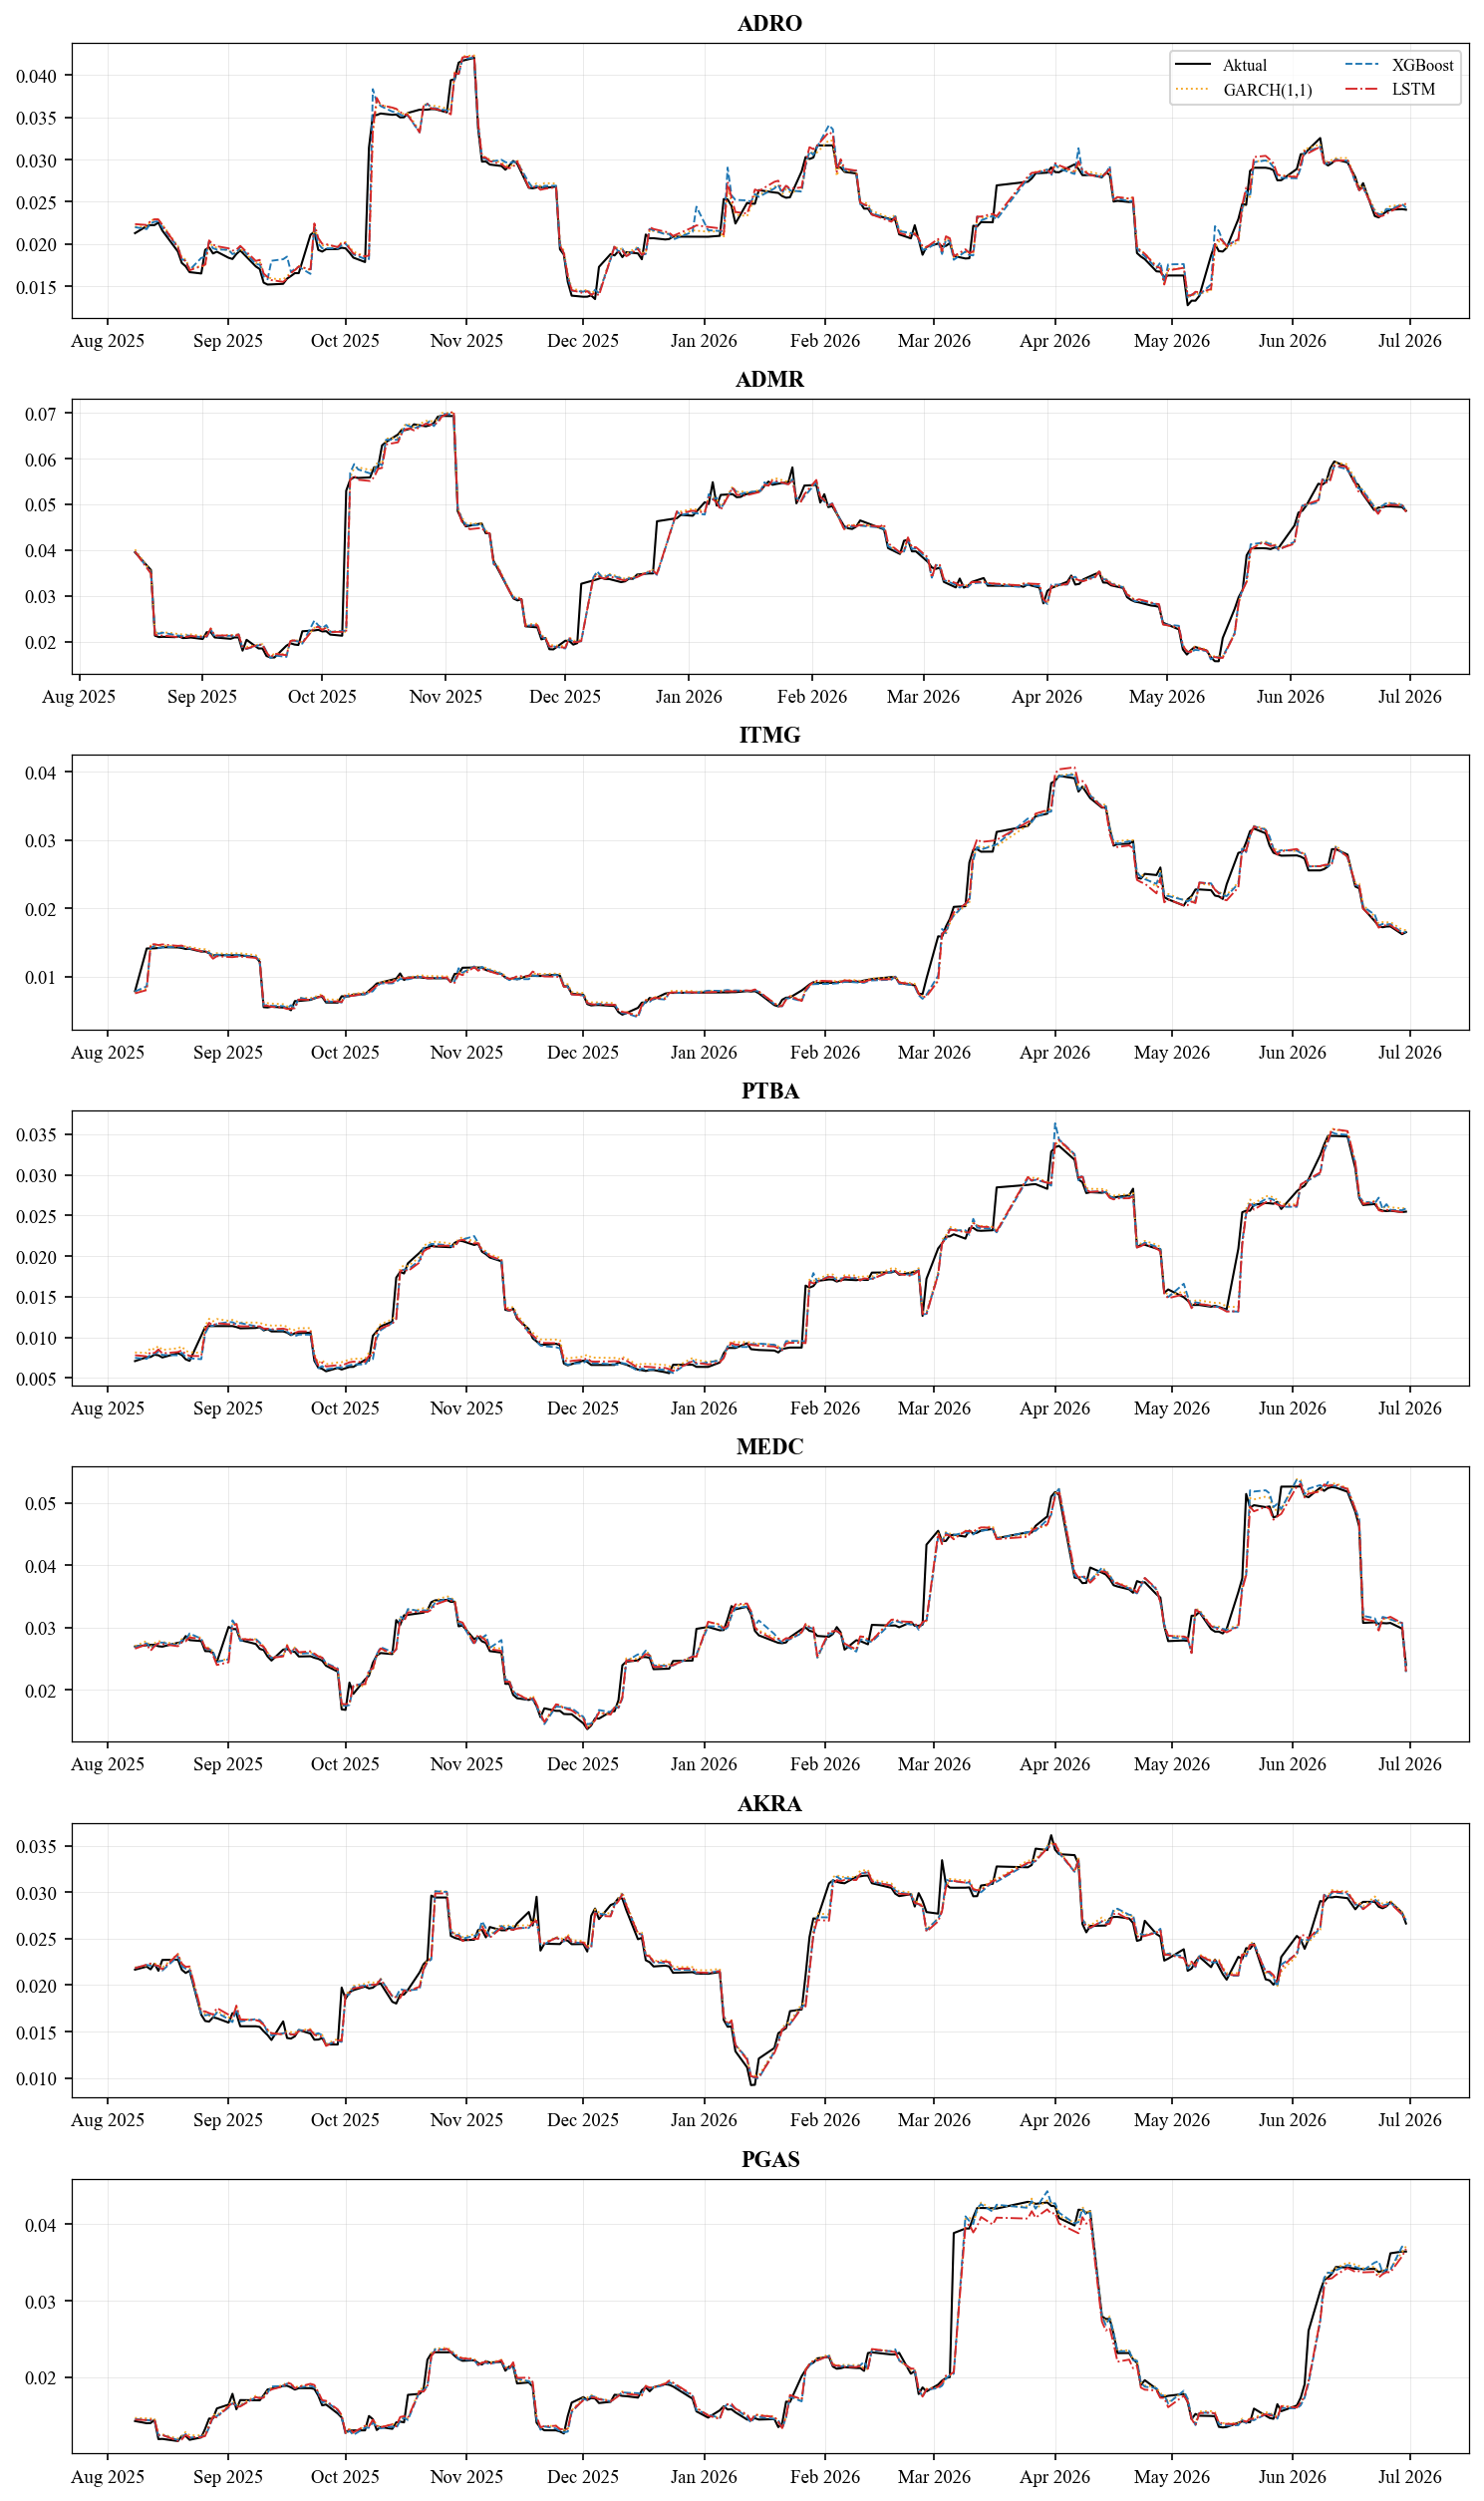

💾 Gambar tersimpan.


In [75]:
import matplotlib.dates as mdates
WARNA = {'Aktual': 'black', 'XGBoost': '#1f77b4', 'LSTM': '#d62728', 'GARCH(1,1)': '#F5A623'}

def plot_emiten(ax, e, legend=True):
    g = df[df.Emiten == e].sort_values('Date')
    for k, ls in [('Aktual', '-'), ('GARCH(1,1)', ':'), ('XGBoost', '--'), ('LSTM', '-.')]:
        ax.plot(g.Date, g[k], color=WARNA[k], lw=1.0 if k == 'Aktual' else 0.9, ls=ls, label=k)
    ax.set_title(e, fontweight='bold'); ax.grid(alpha=0.3, lw=0.4)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    if legend: ax.legend(fontsize=8, ncol=2)

fig, axes = plt.subplots(len(URUTAN_EMITEN), 1, figsize=(10, 2.4 * len(URUTAN_EMITEN)))
for i, (ax, e) in enumerate(zip(axes, URUTAN_EMITEN)): plot_emiten(ax, e, legend=(i == 0))
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_aktual_vs_prediksi_semua_model.png', dpi=300, bbox_inches='tight')
plt.show()
print('💾 Gambar tersimpan.')

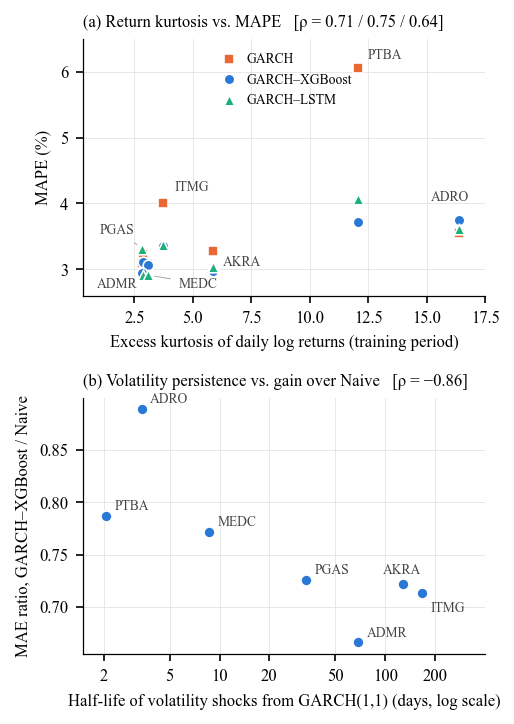

ρ (a) = 0.71 / 0.75 / 0.64 | ρ (b) = -0.86
💾 fig_karakteristik_emiten_vs_akurasi.png tersimpan


In [76]:
# ==============================================================================
# CELL 5B — Gambar karakteristik emiten vs akurasi (→ Fig. 3 artikel)
# ==============================================================================
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator

E = URUTAN_EMITEN
t = tab[tab.Emiten.isin(E)]
mape  = t.pivot(index='Emiten', columns='Model', values='MAPE (%)').reindex(E)
mae   = t.pivot(index='Emiten', columns='Model', values='MAE (1e-3)').reindex(E)
kurt  = df_kar.set_index('Emiten').loc[E, 'Kurtosis return']
hl    = df_par.set_index('Emiten').loc[E, 'Half-life (hari)']
ratio = mae['XGBoost'] / mae['Naive']

with plt.rc_context({'font.family': 'Times New Roman', 'font.size': 8, 'axes.linewidth': 0.6}):
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(3.5, 4.9))

# (a) Kurtosis vs MAPE
SERI = [('GARCH(1,1)', 'GARCH', '#eb6834', 's'),
        ('XGBoost', 'GARCH–XGBoost', '#2a78d6', 'o'),
        ('LSTM', 'GARCH–LSTM', '#1baf7a', '^')]
for kol, lab, c, m in SERI:
    a1.scatter(kurt, mape[kol], s=26, marker=m, color=c, edgecolor='white', linewidth=0.8, label=lab, zorder=3)
LBL = {'ADRO': (15.2, 4.05), 'PTBA': (12.5, 6.2), 'ITMG': (4.2, 4.2), 'AKRA': (6.3, 3.05),
       'PGAS': (1.0, 3.55), 'ADMR': (0.9, 2.72), 'MEDC': (4.4, 2.72)}
for e, (x, y) in LBL.items():
    yy = mape.loc[e, ['GARCH(1,1)', 'XGBoost', 'LSTM']]
    a1.annotate(e, (kurt[e], yy.max() if y > yy.max() else yy.min()), xytext=(x, y), fontsize=6.5, color='#444',
                arrowprops=dict(arrowstyle='-', color='#999', lw=0.4, shrinkB=3) if e in ('PGAS', 'ADMR', 'MEDC') else None)
r_a = [kurt.corr(mape[k], method='spearman') for k in ('GARCH(1,1)', 'XGBoost', 'LSTM')]
a1.set_title(f'(a) Return kurtosis vs. MAPE   [ρ = {r_a[0]:.2f} / {r_a[1]:.2f} / {r_a[2]:.2f}]', fontsize=8, loc='left')
a1.set_xlabel('Excess kurtosis of daily log returns (training period)'); a1.set_ylabel('MAPE (%)')
a1.set_xlim(0.3, 17.5); a1.set_ylim(2.6, 6.5)
a1.legend(fontsize=6.5, frameon=False, loc='upper center', handletextpad=0.3)

# (b) Half-life vs rasio MAE G-XGB / Naive
a2.scatter(hl, ratio, s=28, color='#2a78d6', edgecolor='white', linewidth=0.8, zorder=3)
for e in E:
    off = (4, -9) if e == 'ITMG' else (-10, 5) if e == 'AKRA' else (4, 3)
    a2.annotate(e, (hl[e], ratio[e]), xytext=off, textcoords='offset points', fontsize=6.5, color='#444')
r_b = hl.corr(ratio, method='spearman')
a2.set_title(f'(b) Volatility persistence vs. gain over Naive   [ρ = {r_b:.2f}]'.replace('-', '−'), fontsize=8, loc='left')
a2.set_xscale('log'); a2.set_xlim(1.5, 400)
a2.xaxis.set_major_locator(FixedLocator([2, 5, 10, 20, 50, 100, 200]))
a2.xaxis.set_major_formatter(FixedFormatter(['2', '5', '10', '20', '50', '100', '200']))
a2.xaxis.set_minor_locator(NullLocator())
a2.set_xlabel('Half-life of volatility shocks from GARCH(1,1) (days, log scale)')
a2.set_ylabel('MAE ratio, GARCH–XGBoost / Naive')

for ax in (a1, a2):
    ax.grid(True, color='#e3e3e0', linewidth=0.4); ax.set_axisbelow(True)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
fig.tight_layout(h_pad=1.2)
fig.savefig(DIR_GAMBAR / 'fig_karakteristik_emiten_vs_akurasi.png', dpi=600, bbox_inches='tight')
plt.show()
print(f'ρ (a) = {r_a[0]:.2f} / {r_a[1]:.2f} / {r_a[2]:.2f} | ρ (b) = {r_b:.2f}')
print('💾 fig_karakteristik_emiten_vs_akurasi.png tersimpan')